# 01 · Preprocessing — Qian et al. 2020 Ovarian Cancer (malignant compartment)

Isolate malignant cells, decide a **data-driven** per-sample threshold, integrate patients
(Harmony), embed, and read **Gate 1** (batch mixing + manifold continuity) on the regenerated
embedding itself across an integration-strength sweep — never a single scalar.

*Dataset:* Qian et al. 2020, high-grade serous ovarian cancer, 10x, 4 tumours (`OvC_1..4`).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_'); here Qian2020_Ovarian-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition = Ovarian
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# raw input folder drops the '-1' run suffix (that suffix only namespaces our outputs)
data_name = name[:-2] if name.endswith('-1') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', 'Data_'+data_name)

dataset: Qian2020_Ovarian-1 | category: Ovarian | raw: Data_Qian2020_Ovarian


### Load malignant compartment
Qian et al. annotate cell type directly (`cell_type`); the loader maps `Malignant` calls. Expression
is UMI counts → `normalize_total` → `log1p` (auto-detected from the `UMIcounts` matrix filename).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Qian2020_Ovarian
Done.
full atlas: (16951, 22276)
malignant: (6490, 22276) | samples: 4
expression: X max 7.60 (log1p of normalize_total counts)


### Sample thresholding — the gap-finder's premise is not met here
The general rule finds the largest **multiplicative cliff** in the sorted per-sample malignant counts
and cuts a thin under-populated tail. That rule has a stated premise (C3): a genuinely thin tail exists.
On this dataset the four tumours carry **920–3345** malignant cells each — no thin tail. The largest
multiplicative gap (below) actually falls between the two *largest* samples, so blindly applying the cut
would delete three well-populated tumours and collapse the batch-integration problem to a single sample.
The premise fails, so the derived decision is to **keep all four samples** (every one clears Puram's
≥100 precedent by an order of magnitude).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh_gap = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample malignant counts:', dict(n))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); gap-rule thresh = {thresh_gap}')
print(f'that cut would keep only {int((n>=thresh_gap).sum())}/{len(n)} sample(s) -> premise (thin tail) NOT met')
# min populated sample = %d; all clear a >=100-cell floor by >9x -> keep all
MIN_CELLS = 100
keep = n.index[n >= MIN_CELLS]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'derived threshold: keep all samples with >= {MIN_CELLS} malignant cells -> {len(keep)}/{len(n)} samples, {adata.shape[0]} cells')

sorted per-sample malignant counts: {'14': np.int64(3345), '13': np.int64(1287), '12': np.int64(938), '11': np.int64(920)}
largest multiplicative gap: 3345 -> 1287 (ratio 2.60); gap-rule thresh = 2074
that cut would keep only 1/4 sample(s) -> premise (thin tail) NOT met
derived threshold: keep all samples with >= 100 malignant cells -> 4/4 samples, 6490 cells


### Overdispersion, PCA, and an integration-strength sweep for Harmony `theta`
Malignant single-cell manifolds are dominated by per-patient CNV structure, so the integration strength
`theta` must be **derived**, not inherited. We sweep `theta ∈ {1,2,5,10}` and score mixing with a
**per-neighbourhood iLISI** (inverse-Simpson of the sample composition in each cell's k-NN) — a
distribution, not a single scalar. iLISI ceiling here is not the sample count (4): sample `14` is 52% of
cells, so perfect mixing gives iLISI ≈ 1/Σpᵢ² ≈ 2.9. The read is confirmed **visually** on the
regenerated embedding at each `theta` in the next cell.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA cum. var @ 15/20/30 PCs: %.3f / %.3f / %.3f' % (vr[:15].sum(), vr[:20].sum(), vr[:30].sum()))

codes, uniq = pd.factorize(adata.obs['sample'].astype(str).values); nsamp = len(uniq)
p_global = np.bincount(codes)/len(codes)
ceiling = 1.0/np.sum(p_global**2)
def ilisi(rep, k=30):
    nn = NearestNeighbors(n_neighbors=k).fit(rep).kneighbors(rep, return_distance=False)
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        pr = np.bincount(codes[nn[i]], minlength=nsamp)/k
        out[i] = 1.0/np.sum(pr**2)
    return out
base = np.median(ilisi(adata.obsm['X_pca'][:, :20]))
print(f'iLISI ceiling (max mixing given imbalance) = {ceiling:.2f} | pre-Harmony median = {base:.2f}')
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'harm_th{th}'] = adata.obsm['X_pca_harmony'].copy()
    sweep[th] = np.median(ilisi(adata.obsm[f'harm_th{th}'][:, :20]))
print('theta sweep (median iLISI @20 PCs):', {k: round(v, 2) for k, v in sweep.items()})

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1013 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1013
PCA cum. var @ 15/20/30 PCs: 0.465 / 0.486 / 0.516
iLISI ceiling (max mixing given imbalance) = 2.89 | pre-Harmony median = 1.00
2026-08-05 19:13:00,227 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:13:01,269 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:13:01,307 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 19:13:02,876 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 19:13:04,699 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 19:13:04,938 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19

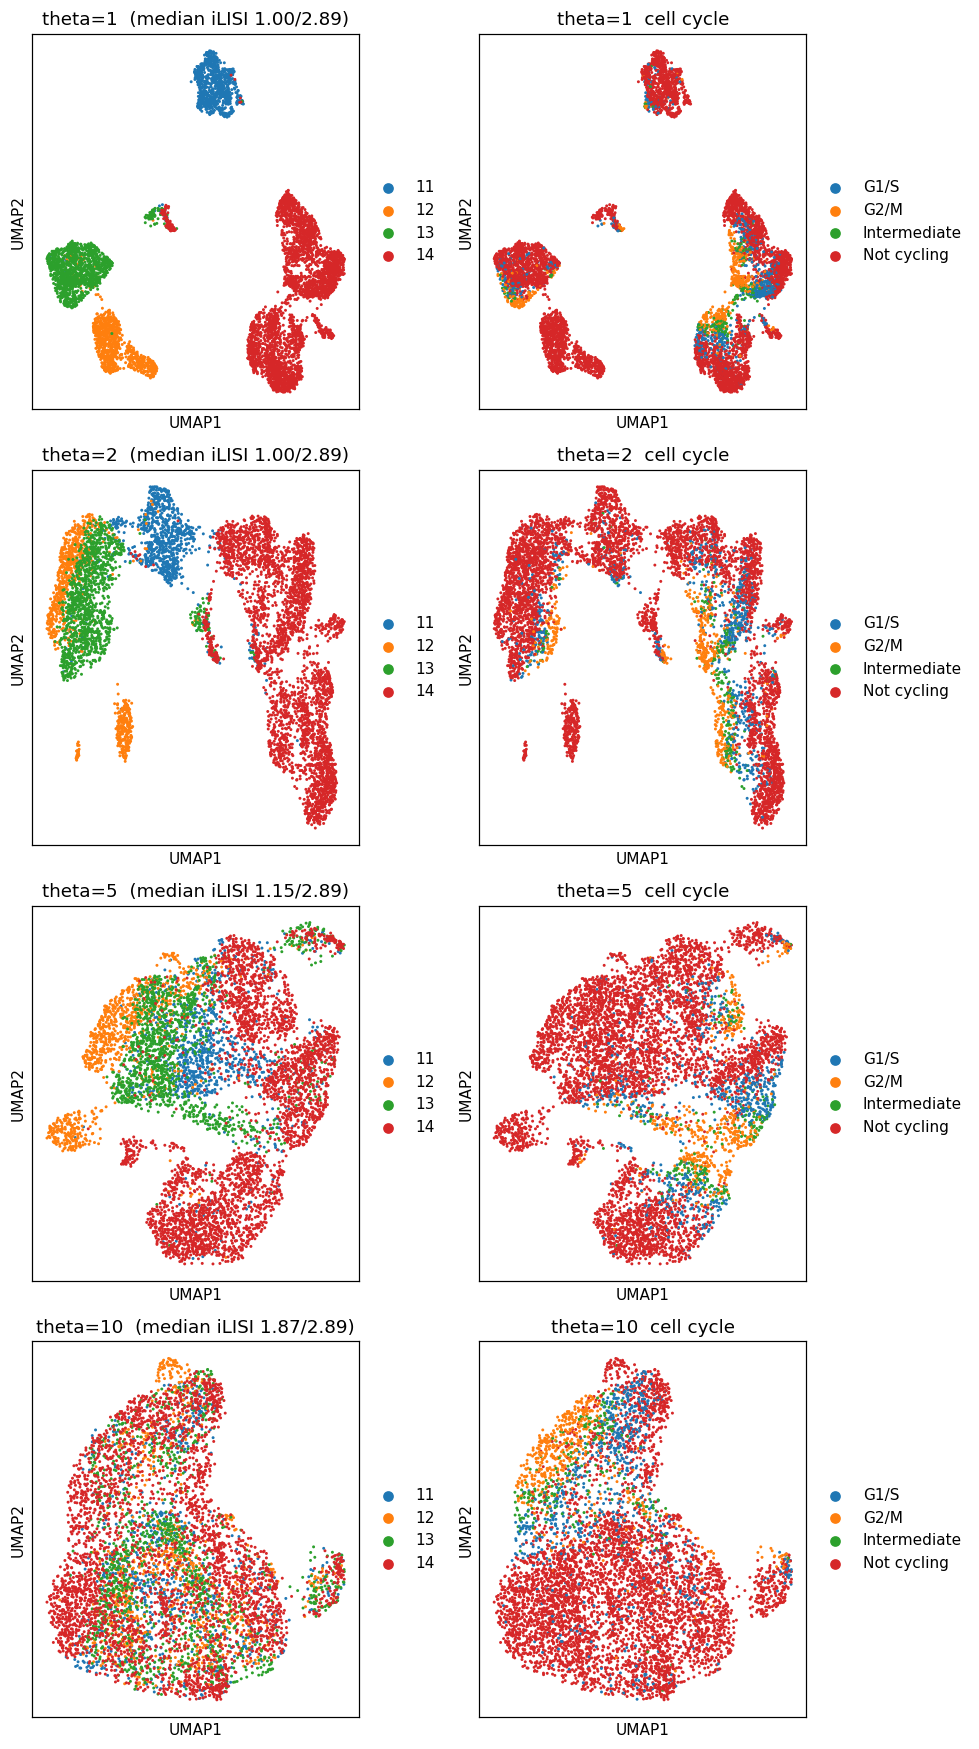

In [6]:
# regenerate the embedding at each theta and read Gate 1 on the embedding itself
fig, axes = plt.subplots(4, 2, figsize=(9, 16))
umaps = {}
for r, th in enumerate([1, 2, 5, 10]):
    sc.pp.neighbors(adata, n_pcs=20, use_rep=f'harm_th{th}', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    umaps[th] = adata.obsm['X_umap'].copy()
    sc.pl.umap(adata, color='sample', size=15, show=False, ax=axes[r, 0],
               title=f'theta={th}  (median iLISI {sweep[th]:.2f}/{ceiling:.2f})')
    sc.pl.umap(adata, color='cell_cycle_phase', size=15, show=False, ax=axes[r, 1],
               title=f'theta={th}  cell cycle')
fig.tight_layout(); plt.show()

**Gate-1 read (on the embedding).** At `theta=1–2` the four tumours occupy separate territories
(per-patient islands) — NO-GO geometry. Mixing rises monotonically through `theta=5`; at **`theta=10`**
the four samples are interspersed across one continuous mass (median iLISI ≈ 1.9 of a 2.9 ceiling, ~65%
of achievable mixing) with no patient-private island. We adopt `theta=10, n_pcs=20`. Cycling cells
(G1/S, G2/M) concentrate in one sub-region — its biology is settled in 02 before the trajectory is
scoped.

In [7]:
# commit theta=10, n_pcs=20
THETA, NPCS = 10, 20
adata.obsm['X_pca_harmony'] = adata.obsm[f'harm_th{THETA}']
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('committed theta =', THETA, '| n_pcs =', NPCS)

committed theta = 10 | n_pcs = 20


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance), take connected components,
keep the largest — stripping only physically detached specks. On this integrated manifold nothing
detaches, confirming the Gate-1 continuity call.

In [8]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands removed:', int((lab != main).sum()), 'cells in', ncomp-1, 'islands')
adata = adata[lab == main].copy()
print('cells after island removal:', adata.shape[0])

detached islands removed: 0 cells in 0 islands
cells after island removal: 6490


### Gate 1 — decision
Four tumours share **one continuous manifold** with no per-patient island after θ=10 integration; the
radius-graph confirms a single connected component. **Gate 1 = GO.**

In [9]:
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} tumours intermixed on one continuous connected manifold at theta={THETA}.')
print('Gate 1 (batch mixing + continuity): GO')

4 tumours intermixed on one continuous connected manifold at theta=10.
Gate 1 (batch mixing + continuity): GO


In [10]:
# save processed data
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (6490, 18208)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample. Intermixing across the
strip is the Gate-1 batch-integration evidence. Orientation is set to the house pseudotime-left→right
convention in 02; here the categorical panel's direction is immaterial.

saved samples.pdf | cells: 6490


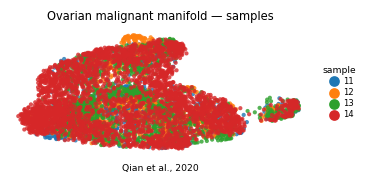

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Ovarian malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0])